# HSA_Cam_B_028.py

## Koschanys DOE  

repeat of B_027 but using Mo_B?011 with relative error model

In [2]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [3]:
from HSA_Cam_B_028_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_011_pyro import kinetics_model, validate_against_holdout, sample_prior

In [4]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [5]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    c2m = torch.tensor([[proposal[3]]])
    c2w = torch.tensor([[proposal[4]]])
    c2i = torch.tensor([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    c2m = torch.tensor([[proposal[3]]])
    c2w = torch.tensor([[proposal[4]]])
    c2i = torch.tensor([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [6]:
exp_run_name = "reliable-grant"  # VI
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [7]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [8]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [9]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [10]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [11]:
display(proposals)

array([[5.25000000e+02, 6.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 7.10000023e-02],
       [5.40000000e+02, 6.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 7.10000023e-02],
       [5.55000000e+02, 6.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 7.10000023e-02],
       [5.85000000e+02, 6.00000000e+00, 2.00000003e-01, 1.00000000e+03,
        1.00000000e+03, 7.10000023e-02],
       [5.25000000e+02, 6.00000000e+00, 2.50000000e-01, 1.00000000e+03,
        1.00000000e+03, 2.00000003e-01],
       [5.40000000e+02, 6.00000000e+00, 2.50000000e-01, 1.00000000e+03,
        1.00000000e+03, 2.00000003e-01],
       [5.55000000e+02, 6.00000000e+00, 2.50000000e-01, 1.00000000e+03,
        1.00000000e+03, 2.00000003e-01],
       [5.85000000e+02, 6.00000000e+00, 2.50000000e-01, 1.00000000e+03,
        1.00000000e+03, 2.00000003e-01],
       [5.25000000e+02, 6.00000000e+00, 4.00000006e-01, 1.00000000e+03,
        1.00000000e+03, 

### Display the results:

In [12]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_22544\2292498082.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


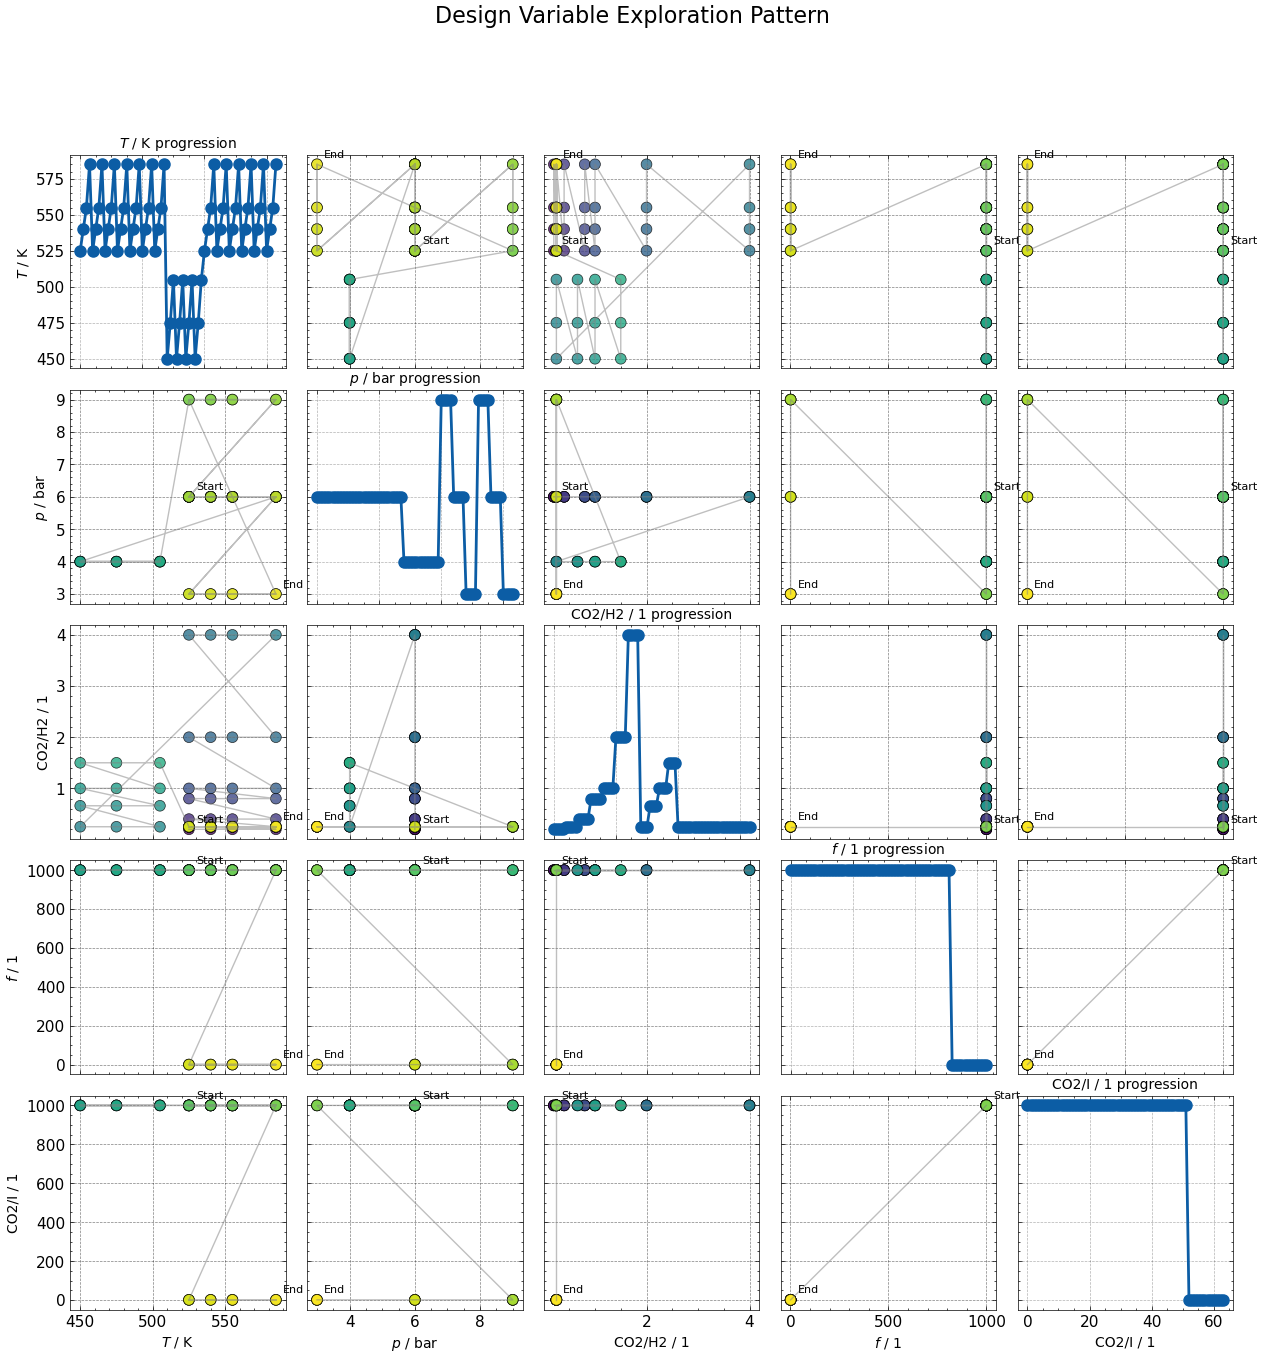

In [13]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [14]:
import xarray

info_gains = []
rel_waics = []
ELPDdatas = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)

    ELPDdata = az.loo(
        idatas[i],
        var_name="r",
        pointwise=True,
        scale="deviance",
    )
    ELPDdatas.append(ELPDdata)
    rel_waics.append(ELPDdata.elpd_loo / idatas[i].observed_data.sizes["obs"])
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:840: UserWarning: The point-wise LOO is the same with the sum LOO, please double check the Observed RV in your model to make sure it returns element-wise logp.
  warnings.warn(
c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling 

[0.43305838 0.65404622 0.15436586 0.08995061 0.49993623 1.25972716
 0.24933566 1.27957816 0.75063964]
5.370637911829462
[0.20899703 0.92071633 0.04603139 0.00540447 0.09177934 0.05929419
 0.01378053 1.20294528 0.22368826]
2.7726367991504466
[ 0.00831833  0.35625852 -0.00977131  0.0444293   0.051384    0.34230959
  0.09913361  0.21940164  2.02490854]
3.1363722299189787
[ 0.11873273  0.38365831  0.06274315 -0.00836173  0.10514478  0.42957161
  0.04815077  0.36092184  0.32499557]
1.8255570299378299
[0.07222631 0.04087092 0.03580523 0.02823193 0.03625034 0.02129143
 0.27272921 0.2555583  0.22273483]
0.9856985061021953
[0.10844278 0.00538213 0.00381487 0.01709167 0.07619388 0.00907338
 0.30307729 0.01605011 0.04695571]
0.5860818238417153
[1.31374756 0.57627216 0.05879066 0.04012237 1.10994749 0.01400563
 1.70443478 0.11530212 1.12260543]
6.055228190778807
[0.14132332 0.59303347 0.1430518  0.04774025 0.09300583 0.03045494
 0.08958412 0.084686   0.11756111]
1.3404408416365015
[0.46283957 0.21

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


In [15]:
for elpd in ELPDdatas:
    print(elpd.loo_i)

<xarray.DataArray 'loo_i' (r_dim_0: 1)> Size: 8B
array([18.54614639])
Coordinates:
  * r_dim_0  (r_dim_0) int64 8B 0
<xarray.DataArray 'loo_i' (r_dim_0: 2)> Size: 16B
array([16.33814621,  4.22058773])
Coordinates:
  * r_dim_0  (r_dim_0) int64 16B 0 1
<xarray.DataArray 'loo_i' (r_dim_0: 3)> Size: 24B
array([ -2.97831154, -12.49997711, -11.06607437])
Coordinates:
  * r_dim_0  (r_dim_0) int64 24B 0 1 2
<xarray.DataArray 'loo_i' (r_dim_0: 4)> Size: 32B
array([ -6.04069614, -10.42124367,  -5.353055  ,   3.80163383])
Coordinates:
  * r_dim_0  (r_dim_0) int64 32B 0 1 2 3
<xarray.DataArray 'loo_i' (r_dim_0: 5)> Size: 40B
array([-24.54570389, -24.03449631, -22.89234543, -17.63484192,
       -24.55430031])
Coordinates:
  * r_dim_0  (r_dim_0) int64 40B 0 1 2 3 4
<xarray.DataArray 'loo_i' (r_dim_0: 6)> Size: 48B
array([-24.1660347 , -22.7066021 , -22.39532661, -19.4614563 ,
       -20.32621956, -23.97315979])
Coordinates:
  * r_dim_0  (r_dim_0) int64 48B 0 1 2 3 4 5
<xarray.DataArray 'loo_i' (r_di

In [16]:
expected_KLDs = [
    trial["predicted_before_obs"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per WAIC')

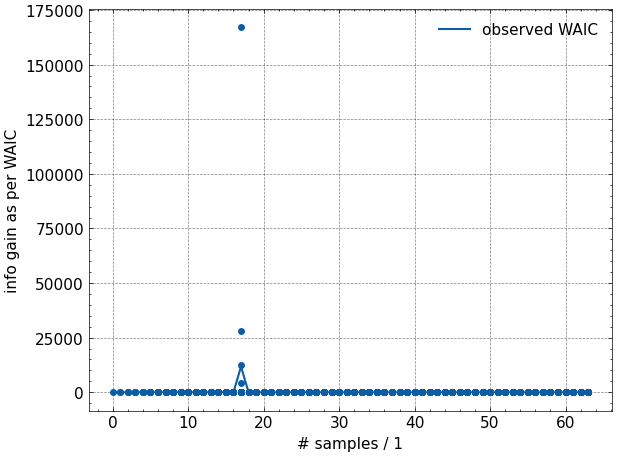

In [17]:
plt.plot(np.arange(len(kldses)), rel_waics, label="observed WAIC")
ax = plt.gca()
for i, elpd in enumerate(ELPDdatas):
    ax.scatter(np.full_like(elpd.loo_i, i), elpd.loo_i, c=f"C0")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per WAIC")

0
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63]
1
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63]
2
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59 60 61 62 63]
3
[ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50
 51 52 53 54 55 56 57 58 59 60 61 62 63]
4
[ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27
 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51
 52 53 54 55 56 57 58 59 60 61 62 63]
5
[ 5  6  7  8  9 10 11 12 13 14 15 16 1

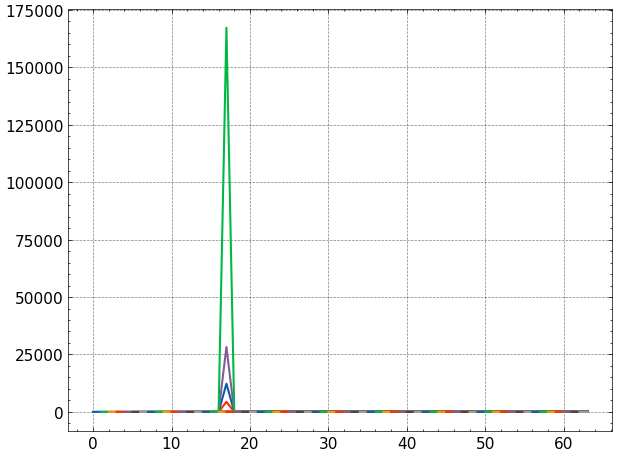

In [18]:
fig, ax = plt.subplots()
for i in range(len(ELPDdatas)):
    print(i)
    x = np.arange(start=i, stop=len(ELPDdatas))
    print(x)
    elpdi = np.array([ELPDdata.loo_i[i] for ELPDdata in ELPDdatas[i:]])
    ax.plot(x, elpdi)

Text(0, 0.5, 'info gain as per KL divergence')

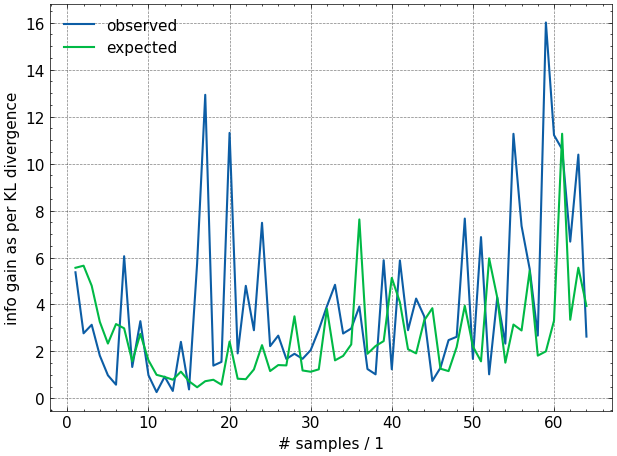

In [19]:
plt.plot(np.arange(len(kldses)) + 1, kldses, label="observed")
plt.plot(np.arange(len(kldses)) + 1, expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

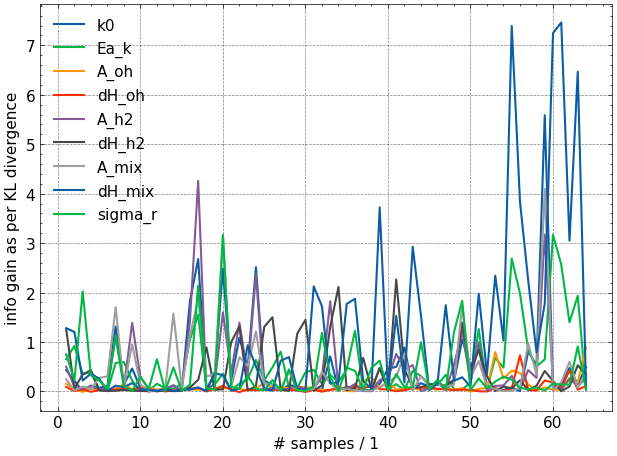

In [20]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [21]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h2', 'A_mix', 'dH_mix', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [22]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Dropdown(description='Parameter:',…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Output()), _dom_classes=('widget-i…

In [24]:
az.summary(idatas[-1], round_to=5)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0,0.00040,0.00003,0.00034,0.00045,0.00000,0.00000,3966.39101,3713.83583,NaN
Ea_k,77493.92188,1999.20288,73739.35938,81246.22656,32.46492,22.93519,3770.03012,3748.09362,NaN
A_oh,0.49921,0.05649,0.39421,0.60250,0.00092,0.00064,3772.97466,3807.92446,NaN
dH_oh,15161.12598,8208.25879,3800.55640,30003.62305,128.85961,181.08954,3781.43244,3921.41030,NaN
A_h2,0.52571,0.04385,0.44560,0.60913,0.00071,0.00050,3816.21548,3601.28571,NaN
dH_h2,-9485.69238,1660.69983,-12658.55762,-6430.95020,27.41525,19.48293,3672.15078,3959.43692,NaN
A_mix,0.95896,0.06009,0.84271,1.06709,0.00094,0.00065,4101.89454,4046.81706,NaN
dH_mix,-6759.56592,1632.90015,-9731.16797,-3675.89038,26.70305,18.57982,3719.60675,3801.43386,NaN
sigma_r,0.05710,0.00483,0.04848,0.06662,0.00008,0.00006,3745.68879,3724.31298,NaN


## load the holdout data

In [25]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_B_002.nc"))
display(test_data)

<xarray.Dataset> Size: 120kB
Dimensions:    (sample: 1000, parameter: 6, species: 5)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float64 8kB ...
    p          (sample, species) float64 40kB ...
    latent_r   (sample) float64 8kB ...
    obs_r      (sample) float64 8kB ...
Attributes:
    noise:    heteroscedastic
    sigma:    0.05

In [26]:
postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(
        idata=idata,
        holdout=test_data,
        num_samples=985,
    )
    postdatas.append(postdata)

torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


torch.Size([1000, 1]) torch.Size([1000, 5]) None


...

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_ppc(
        postdatas[i],
        num_pp_samples=100,
        kind="kde",
        # var_names=["r_pred"],
    )
    ax = plt.gca()
    ax.set_xlim(None, 0.0006)

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Output()), _dom_classes=('widget-i…

In [28]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="u_value",
        bpv=True,
        # var_names=["r_pred"],
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Output()), _dom_classes=('widget-i…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="t_stat",
        bpv=True,
        # var_names=["r_pred"],
        t_stat="mean",
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Output()), _dom_classes=('widget-i…

In [30]:
display(postdatas[0])

Inference data with groups:
	> posterior_predictive
	> observed_data

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="t_stat",
        bpv=True,
        # var_names=["r_pred"],
        t_stat=lambda x: np.mean(np.log(x), axis=0),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), Output()), _dom_classes=('widget-i…

In [ ]:
proposals = test_data.samples.values
r_obs = test_data.obs_r.values
r_lat = test_data.latent_r.values


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    axs[0].scatter(
        proposals[j, 0], r_lat[j], color="green", label="Latent Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=63), IntSlider(value=0, description='Pr…

In [33]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da


RMSEs = {"r": [], "r_pred": []}
for postdata in postdatas:
    RMSE = bRMSE(postdata, "r_pred")
    RMSEs["r_pred"].append(RMSE)
    RMSE = bRMSE(postdata, "r")
    RMSEs["r"].append(RMSE)

RMSEar = {
    "r": np.array([rmse.values for rmse in RMSEs["r"]]),
    "r_pred": np.array([rmse.values for rmse in RMSEs["r_pred"]]),
}

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)


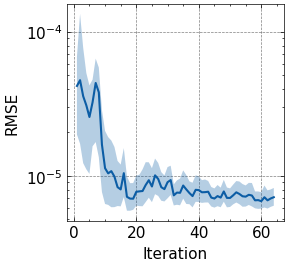

In [34]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r"]) + 1), RMSEar["r"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r"]) + 1),
    np.quantile(RMSEar["r"], 0.025, axis=1),
    np.quantile(RMSEar["r"], 0.975, axis=1),
    alpha=0.3,
)

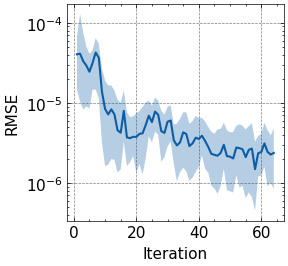

In [35]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r_pred"]) + 1), RMSEar["r_pred"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r_pred"]) + 1),
    np.quantile(RMSEar["r_pred"], 0.025, axis=1),
    np.quantile(RMSEar["r_pred"], 0.975, axis=1),
    alpha=0.3,
)